# 11. Generalized Eigenvectors, Jordan Form and Trace
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The chains $\dim\operatorname{null}N^k$ (blue) and $\operatorname{rank}N^k$ (red) for a nilpotent $9\times9$ matrix built from Jordan blocks of sizes $4,3,2$. The null spaces grow by $3,3,2,1$ dimensions and then stop; the increments, read as column heights, are the conjugate partition of the block sizes (right, a Young diagram with rows of length $4,3,2$).

Text(0.5, 1.0, 'blocks of sizes 4, 3, 2')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


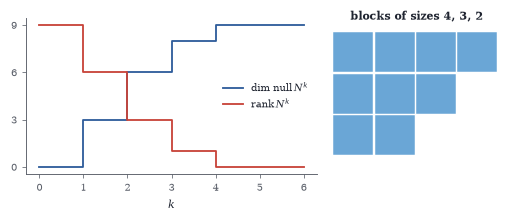

In [2]:
from scipy.linalg import block_diag
def jordan(lam, k):
    return lam * np.eye(k) + np.diag(np.ones(k - 1), 1)
N = block_diag(jordan(0, 4), jordan(0, 3), jordan(0, 2))
ks = np.arange(0, 7)
nul = [9 - np.linalg.matrix_rank(np.linalg.matrix_power(N, k)) for k in ks]
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9), gridspec_kw=dict(width_ratios=[1.6, 1]))
axs[0].step(ks, nul, where="post", color=BLUE, label=r"$\dim\,\mathrm{null}\,N^k$")
axs[0].step(ks, 9 - np.array(nul), where="post", color=RED, label=r"$\mathrm{rank}\,N^k$")
axs[0].set_xlabel("$k$"); axs[0].legend(); axs[0].set_yticks(range(0, 10, 3))
for r, L in enumerate([4, 3, 2]):
    for c in range(L):
        axs[1].add_patch(plt.Rectangle((c, -r), 0.92, 0.92, color=SKY))
axs[1].set_xlim(-0.2, 4.2); axs[1].set_ylim(-2.3, 1.1); axs[1].set_aspect("equal"); axs[1].axis("off")
axs[1].set_title("blocks of sizes 4, 3, 2", fontsize=7)

In [3]:
# Characteristic vs minimal polynomial for an operator with blocks J_3(2), J_1(2), J_2(5).
T = block_diag(jordan(2, 3), jordan(2, 1), jordan(5, 2))
n = T.shape[0]
for lam in [2, 5]:
    alg = n - np.linalg.matrix_rank(np.linalg.matrix_power(T - lam * np.eye(n), n))
    geo = n - np.linalg.matrix_rank(T - lam * np.eye(n))
    m = next(k for k in range(1, n + 1)
             if np.linalg.matrix_rank(np.linalg.matrix_power(T - lam * np.eye(n), k)) ==
                np.linalg.matrix_rank(np.linalg.matrix_power(T - lam * np.eye(n), k + 1)))
    print(f"lambda={lam}: algebraic {alg}, geometric {geo}, exponent in minimal polynomial {m}")
print("characteristic polynomial coefficients:", np.poly(T).round(6))
q = np.poly(T); qT = sum(c * np.linalg.matrix_power(T, len(q) - 1 - i) for i, c in enumerate(q))
print("Cayley-Hamilton, max |q(T)| =", np.abs(qT).max())

lambda=2: algebraic 4, geometric 2, exponent in minimal polynomial 3
lambda=5: algebraic 2, geometric 1, exponent in minimal polynomial 2
characteristic polynomial coefficients: [   1.  -18.  129. -472.  936. -960.  400.]
Cayley-Hamilton, max |q(T)| = 0.0


A Jordan form, drawn as a matrix. Three eigenvalues; for the eigenvalue $2$ there are blocks of sizes $3$ and $1$, for $5$ a single block of size $2$, for $-1$ two blocks of size $1$. Diagonal entries (eigenvalues) in blue; superdiagonal ones in red. The block sizes for each eigenvalue are determined by the ranks of powers of $T-\lambda I$.

[]

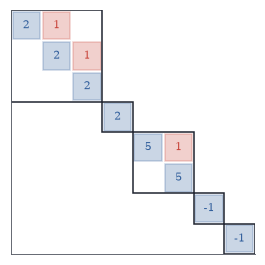

In [4]:
J = block_diag(jordan(2, 3), jordan(2, 1), jordan(5, 2), jordan(-1, 1), jordan(-1, 1))
n = J.shape[0]
fig, ax = plt.subplots(figsize=(W * 0.5, W * 0.5))
ax.imshow(np.zeros_like(J), cmap="Greys", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(J):
    if v != 0:
        col = BLUE if i == j else RED
        ax.add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, color=col, alpha=0.25))
        ax.text(j, i, f"{v:g}", ha="center", va="center", fontsize=7, color=col)
start = 0
for size in [3, 1, 2, 1, 1]:
    ax.add_patch(plt.Rectangle((start - 0.5, start - 0.5), size, size, fill=False, ec=INK, lw=1)); start += size
ax.set_xticks([]); ax.set_yticks([])

Transient growth. The norm $\lVert J^k\rVert$ for a $10\times10$ Jordan block $J=0.85I+N$: although $\rho(J)=0.85<1$, the norm first climbs by more than five orders of magnitude, peaking near $k\approx 40$, before exponential decay wins. The dashed line is $0.85^k$, what one would naively expect.

(1e-06, 10000000.0)

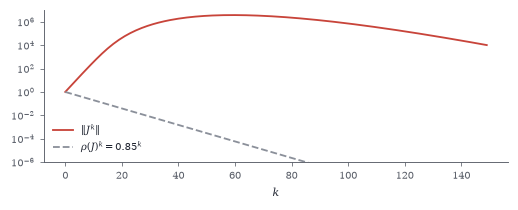

In [5]:
J10 = jordan(0.85, 10)
ks = np.arange(0, 150)
norms = [np.linalg.norm(np.linalg.matrix_power(J10, k), 2) for k in ks]
fig, ax = plt.subplots(figsize=(W, 1.8))
ax.semilogy(ks, norms, color=RED, label=r"$\|J^k\|$")
ax.semilogy(ks, 0.85 ** ks, "--", color=GRAY, label=r"$\rho(J)^k=0.85^k$")
ax.set_xlabel("$k$"); ax.legend(); ax.set_ylim(1e-6, 1e7)

Eigenvalues of $J_n(0)+\varepsilon E_{n1}$ for $n=12$ and $\varepsilon=10^{-12},10^{-8},10^{-4}$: an $\varepsilon$-perturbation of a nilpotent Jordan block moves its eigenvalue $0$ (multiplicity $12$) onto a circle of radius $\varepsilon^{1/12}$ (dashed). Tiny perturbations, huge movement.

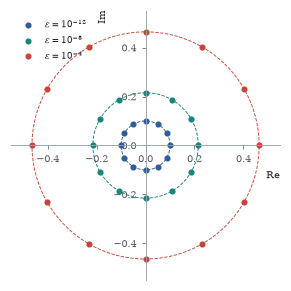

In [6]:
fig, ax = plt.subplots(figsize=(W * 0.55, W * 0.55))
complex_plane(ax, 0.55, ticks=True)
for e, col in [(1e-12, BLUE), (1e-8, TEAL), (1e-4, RED)]:
    M = jordan(0, 12); M[-1, 0] = e
    lam = np.linalg.eigvals(M); ax.plot(lam.real, lam.imag, "o", color=col, ms=3, label=rf"$\varepsilon=10^{{{int(np.log10(e))}}}$")
    th = np.linspace(0, 2 * np.pi, 200); r = e ** (1 / 12); ax.plot(r * np.cos(th), r * np.sin(th), "--", color=col, lw=0.6)
ax.legend(fontsize=6, loc="upper left")

Hutchinson's trace estimator for a $1000\times1000$ positive semidefinite matrix with rapidly decaying eigenvalues. Grey, individual runs; blue, the average relative error over runs, decreasing like $1/\sqrt{m}$ (dashed) with the number $m$ of matrix–vector products.

Text(0, 0.5, 'relative error')

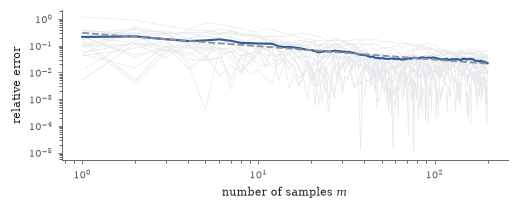

In [7]:
rng = np.random.default_rng(0)
n = 1000
Q, _ = np.linalg.qr(rng.normal(size=(n, n)))
A = (Q * (1.0 / np.arange(1, n + 1) ** 1.2)) @ Q.T
tr = np.trace(A); ms = np.arange(1, 201)
errs = []
fig, ax = plt.subplots(figsize=(W, 1.8))
for run in range(20):
    Z = rng.choice([-1.0, 1.0], size=(n, ms[-1]))
    est = np.cumsum(np.einsum("ij,ij->j", Z, A @ Z)) / ms
    e = np.abs(est - tr) / tr; errs.append(e); ax.loglog(ms, e, color=LIGHT, lw=0.5)
ax.loglog(ms, np.mean(errs, 0), color=BLUE, lw=1.4); ax.loglog(ms, 0.3 / np.sqrt(ms), "--", color=GRAY)
ax.set_xlabel("number of samples $m$"); ax.set_ylabel("relative error")

In [8]:
T = np.zeros((5, 5)); T[0, 1], T[1, 2], T[2, 3], T[3, 4] = 2, 3, -1, 4
R = np.eye(5) + T / 2 - T @ T / 8 + np.linalg.matrix_power(T, 3) / 16 - 5 * np.linalg.matrix_power(T, 4) / 128
print("R^2 = I + T:", np.allclose(R @ R, np.eye(5) + T))

R^2 = I + T: True


Entries of $e^{tJ}$ for $J=J_3(-0.5)$: the diagonal entry $e^{-t/2}$ decays monotonically, but the superdiagonal entries $te^{-t/2}$ and $\frac{t^2}{2}e^{-t/2}$ rise first, reaching $2/e\approx0.74$ and $8/e^2\approx1.08$ before decaying.

Text(0.5, 0, '$t$')

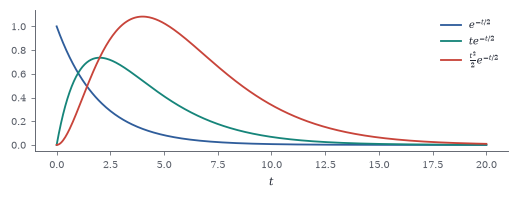

In [9]:
t = np.linspace(0, 20, 400)
fig, ax = plt.subplots(figsize=(W, 1.7))
for f, lab, col in [(np.exp(-t / 2), r"$e^{-t/2}$", BLUE), (t * np.exp(-t / 2), r"$te^{-t/2}$", TEAL), (t ** 2 / 2 * np.exp(-t / 2), r"$\frac{t^2}{2}e^{-t/2}$", RED)]:
    ax.plot(t, f, color=col, label=lab)
ax.legend(); ax.set_xlabel("$t$")

In [10]:
def jordan_blocks(A, lam, tol=1e-8):
    n = A.shape[0]; M = A - lam * np.eye(n)
    r = [n] + [np.linalg.matrix_rank(np.linalg.matrix_power(M, k), tol) for k in range(1, n + 2)]
    sizes = {}
    for k in range(1, n + 1):
        cnt = (r[k - 1] - r[k]) - (r[k] - r[k + 1])
        if cnt: sizes[k] = int(cnt)
    return sizes
J = block_diag(jordan(2, 3), jordan(2, 1), jordan(5, 2))
S = np.random.default_rng(1).normal(size=(6, 6))
A = S @ J @ np.linalg.inv(S)
print("blocks for 2:", jordan_blocks(A, 2.0), "  blocks for 5:", jordan_blocks(A, 5.0))

blocks for 2: {1: 1, 3: 1}   blocks for 5: {2: 1}
